### 1. Install NEURON and Download the BBP Model
We will install NEURON, clone the classic BBP L5PC model from ModelDB (Hay et al. 2011), and compile the `.mod` mechanisms.

In [5]:
#@title NEURON install (launch only once) and git-clone a BBP model
# Note: Google Colab gives you access to an "instance".
# This is a virtual machine ("container" would be more correct) that runs
# Linux with already a Python installation.
!pip install neuron plotly ipywidgets matplotlib

# Clone the Hay 2011 BBP L5PC model
!git clone https://github.com/ModelDBRepository/139653.git bbp_l5pc

# Compile the mechanisms (mod files)
!cd bbp_l5pc && nrnivmodl mod

Cloning into 'bbp_l5pc'...
remote: Enumerating objects: 81, done.
remote: Counting objects: 100% (22/22), done.
remote: Compressing objects: 100% (21/21), done.
remote: Total 81 (delta 5), reused 7 (delta 1), pack-reused 59 (from 1)
Receiving objects: 100% (81/81), 652.07 KiB | 4.13 MiB/s, done.
Resolving deltas: 100% (12/12), done.
/content/bbp_l5pc/bbp_l5pc
cfiles =
Mod files: "mod/CaDynamics_E2.mod" "mod/Ca_HVA.mod" "mod/Ca_LVAst.mod" "mod/epsp.mod" "mod/Ih.mod" "mod/Im.mod" "mod/K_Pst.mod" "mod/K_Tst.mod" "mod/Nap_Et2.mod" "mod/NaTa_t.mod" "mod/NaTs2_t.mod" "mod/SK_E2.mod" "mod/SKv3_1.mod"

Creating 'x86_64' directory for .o files.

MODOBJS= ./CaDynamics_E2.o ./Ca_HVA.o ./Ca_LVAst.o ./epsp.o ./Ih.o ./Im.o ./K_Pst.o ./K_Tst.o ./Nap_Et2.o ./NaTa_t.o ./NaTs2_t.o ./SK_E2.o ./SKv3_1.o
 -> Compiling mod_func.cpp
 -> NMODL ../mod/CaDynamics_E2.mod
 -> NMODL ../mod/Ca_HVA.mod
Translating CaDynamics_E2.mod into /content/bbp_l5pc/bbp_l5pc/x86_64/CaDynamics_E2.cpp
 -> NMODL ../mod/Ca_LVAst.mo

### 2. Load the Model into NEURON
We load the standard HOC templates and initialize the morphology.

In [6]:
#@title Load HOC templates and morphology
import os
from neuron import h, gui

# Change to the model directory so NEURON can find local files
if os.path.basename(os.getcwd()) != 'bbp_l5pc':
    os.chdir('bbp_l5pc')

# Load standard run and 3D import libraries
h.load_file('stdrun.hoc')
h.load_file('import3d.hoc')

# Load compiled mechanisms only if not already loaded to prevent errors
if not hasattr(h, 'CaDynamics_E2'):
    h.nrn_load_dll('x86_64/libnrnmech.so')

# Load BBP templates
h.load_file('models/L5PCbiophys3.hoc')
h.load_file('models/L5PCtemplate.hoc')

# Instantiate the cell with the provided morphology
cell = h.L5PCtemplate('morphologies/cell1.asc')
print("Model loaded successfully!")


Model loaded successfully!


### 3. Display 3D Morphology
Using NEURON's built-in Plotly support, we can visualize the intricate morphology of the pyramidal cell.

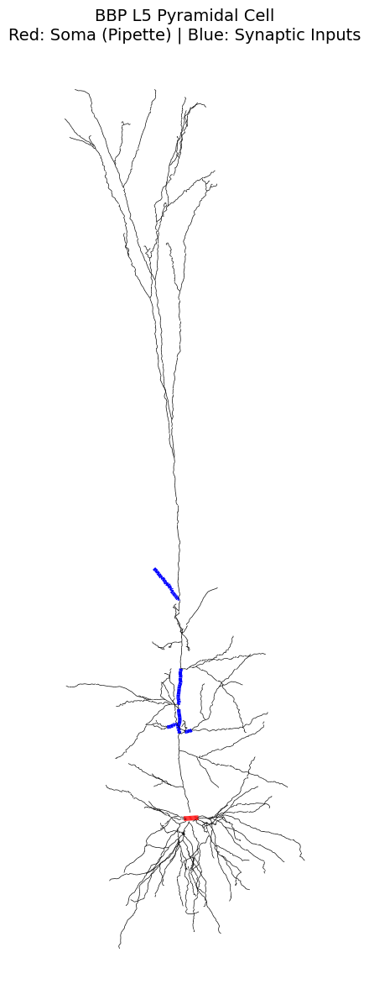

In [7]:
#@title Plot the morphology of the (BBP) model for a rat cortical L5 pyramidal neuron
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import random

# Pre-select 5 apical dendrites for the forthcoming synaptic inputs
random.seed(42)
target_dends = [cell.apic[random.randint(0, len(cell.apic)-1)] for _ in range(5)]

# Set up the Matplotlib figure
fig, ax = plt.subplots(figsize=(8, 12))
lines = []
colors = []
linewidths = []

# Extract 2D coordinates directly for perfect alignment and control
for sec in h.allsec():
    is_soma = 'soma' in sec.name()
    is_target = sec in target_dends

    # Style: Soma is thick red, targets are thick blue, rest is thin black
    if is_soma:
        c, lw = 'red', 4.0
    elif is_target:
        c, lw = 'blue', 3.0
    else:
        c, lw = 'black', 0.5

    n3d = sec.n3d()
    for i in range(n3d - 1):
        # We plot X and Y strictly, ensuring apical dendrites are vertical
        x0, y0 = sec.x3d(i), sec.y3d(i)
        x1, y1 = sec.x3d(i+1), sec.y3d(i+1)
        lines.append([(x0, y0), (x1, y1)])
        colors.append(c)
        linewidths.append(lw)

# Add all lines to the plot
lc = LineCollection(lines, colors=colors, linewidths=linewidths)
ax.add_collection(lc)
ax.autoscale()
ax.set_aspect('equal')
ax.axis('off')

ax.set_title('BBP L5 Pyramidal Cell\nRed: Soma (Pipette) | Blue: Synaptic Inputs', fontsize=14)
plt.tight_layout()
plt.show()


### 4. Interactive Simulation with Sliders
We will inject a current pulse into the soma and distribute a few random synapses (NetStim + ExpSyn) along the apical dendrites. Using `ipywidgets`, we can easily control the amplitude and synaptic weight.

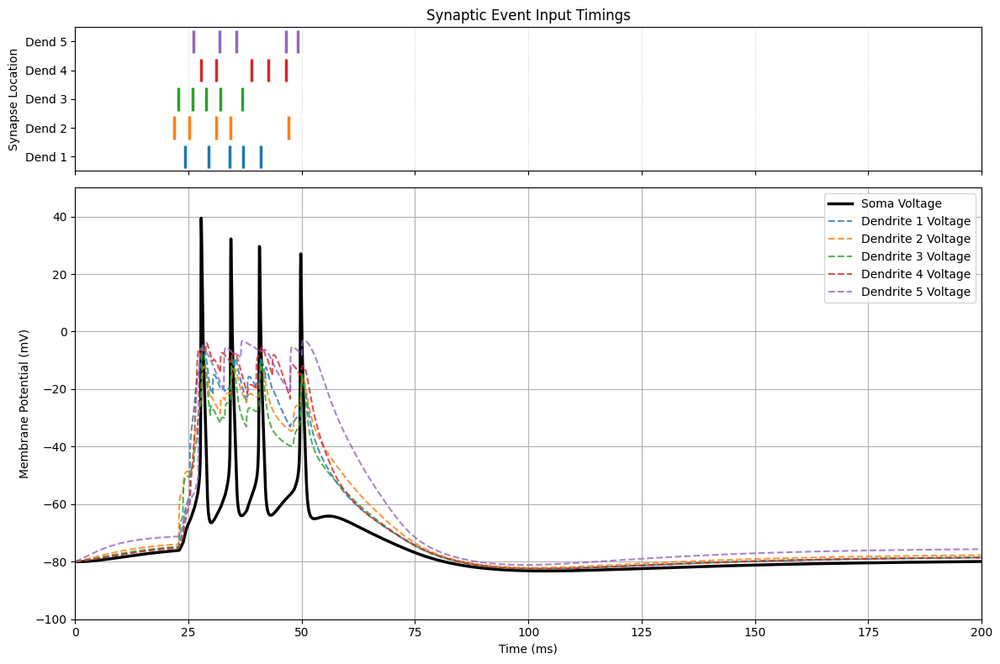

In [39]:
#@title Simulate the model, somatic current injection { run: "auto" }
import random
import matplotlib.pyplot as plt

# --- Parameters ---
soma_current = 0 #@param {type:"slider", min:0.0, max:2.0, step:0.05}
s3d_weight = 0.015
syn_weight = 0.04 #@param {type:"slider", min:0.0, max:0.1, step:0.005}

# --- Stimulation Setup ---
# Only create the objects ONCE to prevent them from accumulating on the cell
if 'stim' not in globals() or not hasattr(stim, 'hname'):
    stim = h.IClamp(cell.soma[0](0.5))

    synapses = []
    netstims = []
    netcons = []
    dends_to_use = target_dends if 'target_dends' in globals() else [cell.apic[random.randint(0, len(cell.apic)-1)] for _ in range(5)]

    for dend in dends_to_use:
        syn = h.ExpSyn(dend(0.5))
        syn.tau = 2.0
        syn.e = 0

        ns = h.NetStim()
        ns.number = 5
        ns.start = 20 + random.uniform(0, 10)
        ns.interval = 5
        ns.noise = 0.5

        nc = h.NetCon(ns, syn)

        synapses.append(syn)
        netstims.append(ns)
        netcons.append(nc)

    t_vec = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(cell.soma[0](0.5)._ref_v)

    # Record local dendritic membrane potentials (local PSPs)
    v_dends = []
    for dend in dends_to_use:
        v_dends.append(h.Vector().record(dend(0.5)._ref_v))
else:
    # Fallback to ensure v_dends is populated if the setup block is skipped
    if 'v_dends' not in globals():
        dends_to_use = target_dends if 'target_dends' in globals() else [cell.apic[random.randint(0, len(cell.apic)-1)] for _ in range(5)]
        v_dends = []
        for dend in dends_to_use:
            v_dends.append(h.Vector().record(dend(0.5)._ref_v))

# Record spike/event times from each NetStim to visualize in the top panel
event_vectors = [h.Vector() for _ in netcons]
for nc, ev_vec in zip(netcons, event_vectors):
    nc.record(ev_vec)

# Update parameters based on current slider values
stim.delay = 50
stim.dur = 100
stim.amp = soma_current # nA

for nc in netcons:
    nc.weight[0] = syn_weight

# --- Run Simulation ---
h.celsius = 34.0
# Initialize at -80 mV to prevent the BBP model from firing a rebound/transient spike
h.v_init = -80
h.finitialize(-80)
h.continuerun(200)

# --- Plotting ---
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [1, 3]})

# Define distinct colors matching dendrites 1 to 5
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

# Top Panel: Synaptic Input Timing (Raster Plot)
for idx, ev_vec in enumerate(event_vectors):
    spike_times = list(ev_vec)
    ax0.vlines(spike_times, idx + 0.6, idx + 1.4, colors=colors[idx % len(colors)], linewidth=2.5)

ax0.set_yticks(range(1, len(event_vectors) + 1))
ax0.set_yticklabels([f'Dend {i+1}' for i in range(len(event_vectors))])
ax0.set_ylabel('Synapse Location')
ax0.set_title('Synaptic Event Input Timings')
ax0.set_ylim(0.5, len(event_vectors) + 0.5)
ax0.grid(True, axis='x', linestyle=':', alpha=0.6)

# Bottom Panel: Membrane Potentials
ax1.plot(t_vec, v_soma, label='Soma Voltage', color='black', linewidth=2.5)
for idx, v_dend in enumerate(v_dends):
    ax1.plot(t_vec, v_dend, label=f'Dendrite {idx+1} Voltage', color=colors[idx % len(colors)], linestyle='--', alpha=0.8)

ax1.xlabel = 'Time (ms)'
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Membrane Potential (mV)')
ax1.legend(loc='best')
ax1.set_xlim(0, 200)
ax1.set_ylim(-100, 50)
ax1.grid(True)

plt.tight_layout()
plt.show()

In [40]:
#@title Generate Spatiotemporal Depolarization Movie { run: "auto" }
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.collections import LineCollection
from IPython.display import HTML, display

# --- Parameters ---
#soma_amp = 0.5 #@param {type:"slider", min:0.0, max:2.0, step:0.05}
#syn_weight = 0.01 #@param {type:"slider", min:0.0, max:0.1, step:0.005}
soma_amp = soma_current

print(f"Generating movie with Soma I = {soma_amp} nA, Syn Weight = {syn_weight}")

# 2. Apply parameters to the stimulation objects
stim.amp = soma_amp
for nc in netcons:
    nc.weight[0] = syn_weight

# 3. Setup Recording for all 3D segments
lines = []
segments = []
v_vecs = []

# Map 3D shape and record voltage at the corresponding 1D segments
for sec in h.allsec():
    n3d = sec.n3d()
    for i in range(n3d - 1):
        x0, y0 = sec.x3d(i), sec.y3d(i)
        x1, y1 = sec.x3d(i+1), sec.y3d(i+1)
        lines.append([(x0, y0), (x1, y1)])

        # Map 3D segment to 1D normalized position
        arc_mid = (sec.arc3d(i) + sec.arc3d(i+1)) / 2.0
        seg_x = arc_mid / sec.L if sec.L > 0 else 0.5
        segments.append(sec(seg_x))

for seg in segments:
    v_vecs.append(h.Vector().record(seg._ref_v))

t_vec = h.Vector().record(h._ref_t)

# 4. Run Simulation
h.celsius = 34.0
h.finitialize(-70)
h.continuerun(100) # Run for 100 ms to keep the movie generation fast

# 5. Process Data for Animation
v_data = np.array([np.array(vec) for vec in v_vecs])
t_data = np.array(t_vec)

# Subsample data to ~1 frame per ms to keep the animation smooth and light
dt = h.dt
step = max(1, int(1.0 / dt))
v_frames = v_data[:, ::step]
t_frames = t_data[::step]

# 6. Create Animation
fig, ax = plt.subplots(figsize=(8, 10))

# False color mapping from -80 mV (blue) to +40 mV (red)
lc = LineCollection(lines, cmap='jet', norm=plt.Normalize(vmin=-80, vmax=40))
lc.set_array(v_frames[:, 0])
ax.add_collection(lc)
ax.autoscale()
ax.set_aspect('equal')
ax.axis('off')

cbar = fig.colorbar(lc, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Membrane Potential (mV)')
title = ax.set_title(f'Time: {t_frames[0]:.1f} ms')

def animate(i):
    lc.set_array(v_frames[:, i])
    title.set_text(f'Time: {t_frames[i]:.1f} ms')
    return lc, title

# Create the animation object
anim = FuncAnimation(fig, animate, frames=len(t_frames), interval=50, blit=True)
plt.close(fig) # Prevent static plot from displaying

# Display as interactive HTML video with CSS fix for buttons
css_fix = "<style>.animation button { color: black !important; font-weight: bold; }</style>"
display(HTML(css_fix + anim.to_jshtml()))


Generating movie with Soma I = 0 nA, Syn Weight = 0.04
